In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.stats import f_oneway

In [81]:
# 1. Зареждане на Excel файла
file_path = 'data/data.xlsx'
df = pd.read_excel(file_path)

print(f"Общ брой записи в таблицата: {len(df)}")
print(f"Уникални училища: {df['Училище'].nunique()}")
print(f"Налични години: {df['Година'].unique()}")

Общ брой записи в таблицата: 320
Уникални училища: 40
Налични години: <StringArray>
['2025-2026', '2024-2025', '2023-2024', '2022-2023', '2021-2022', '2020-2021',
 '2019-2020', '2018-2019']
Length: 8, dtype: str


In [82]:
# 2. Обща статистика за целия град (всички училища)
print("=== СТАТИСТИКА ЗА ЦЕЛИЯ ГРАД (Всички училища) ===")
city_stats = df[['БЕЛ', 'МАТ']].agg(['mean', 'median', 'std', 'min', 'max'])
display(city_stats.round(2))
print("\n" + "="*50 + "\n")

=== СТАТИСТИКА ЗА ЦЕЛИЯ ГРАД (Всички училища) ===


,БЕЛ,МАТ
mean,60.99,45.51
median,64.18,44.88
std,16.60,17.96
min,7.58,8.82
max,93.22,96.95


In [83]:
# 3. Намиране на топ 15 училища въз основа на средния резултат (БЕЛ + МАТ) за целия период
school_avg = df.groupby('Училище')[['БЕЛ', 'МАТ']].mean().mean(axis=1).sort_values(ascending=False)
top_15_schools = school_avg.head(15).index.tolist()

print("\n--- ТОП 15 УЧИЛИЩА ВЪВ ВАРНА ---")
for i, school in enumerate(top_15_schools, 1):
    print(f"{i}. {school}")


--- ТОП 15 УЧИЛИЩА ВЪВ ВАРНА ---
1. МГ "Д-р Петър Берон"
2. ОУ "П. Р. Славейков"
3. ОУ "Св. Св. Кирил и Методий"
4. VII ОУ "Найден Геров"
5. ОУ "Захари Стоянов"
6. СУ "Ал. С. Пушкин"
7. СУ "Св. Климент Охридски"
8. ОУ "Г. С. Раковски"
9. ЧОУ "Малкият принц"
10. СУ "Гео Милев"
11. СУХНИ "Константин Преславски"
12. III ОУ "Ангел Кънчев"
13. ОУ "Черноризец Храбър"
14. ЧСИ "Мечтатели"
15. ОУ "Васил Друмев"


In [84]:
# 3. Филтриране на основния DataFrame само за тези топ 15 училища
df_top15 = df[df['Училище'].isin(top_15_schools)]
print(f"\nФилтриран датасет за топ 15 училища брой редове: {len(df_top15)}")


Филтриран датасет за топ 15 училища брой редове: 120


In [85]:
# 3. Изчисляване на основни статистики за Топ 15 училищата
print("\n=== СТАТИСТИКА САМО ЗА ТОП 15 УЧИЛИЩА ===")
top15_stats = df_top15[['БЕЛ', 'МАТ']].agg(['mean', 'median', 'std', 'min', 'max'])
display(top15_stats.round(2))
print("\n" + "="*50 + "\n")


=== СТАТИСТИКА САМО ЗА ТОП 15 УЧИЛИЩА ===


,БЕЛ,МАТ
mean,74.57,62.13
median,74.37,61.24
std,6.32,12.78
min,59.77,28.86
max,93.22,96.95


<Figure size 1400x700 with 0 Axes>

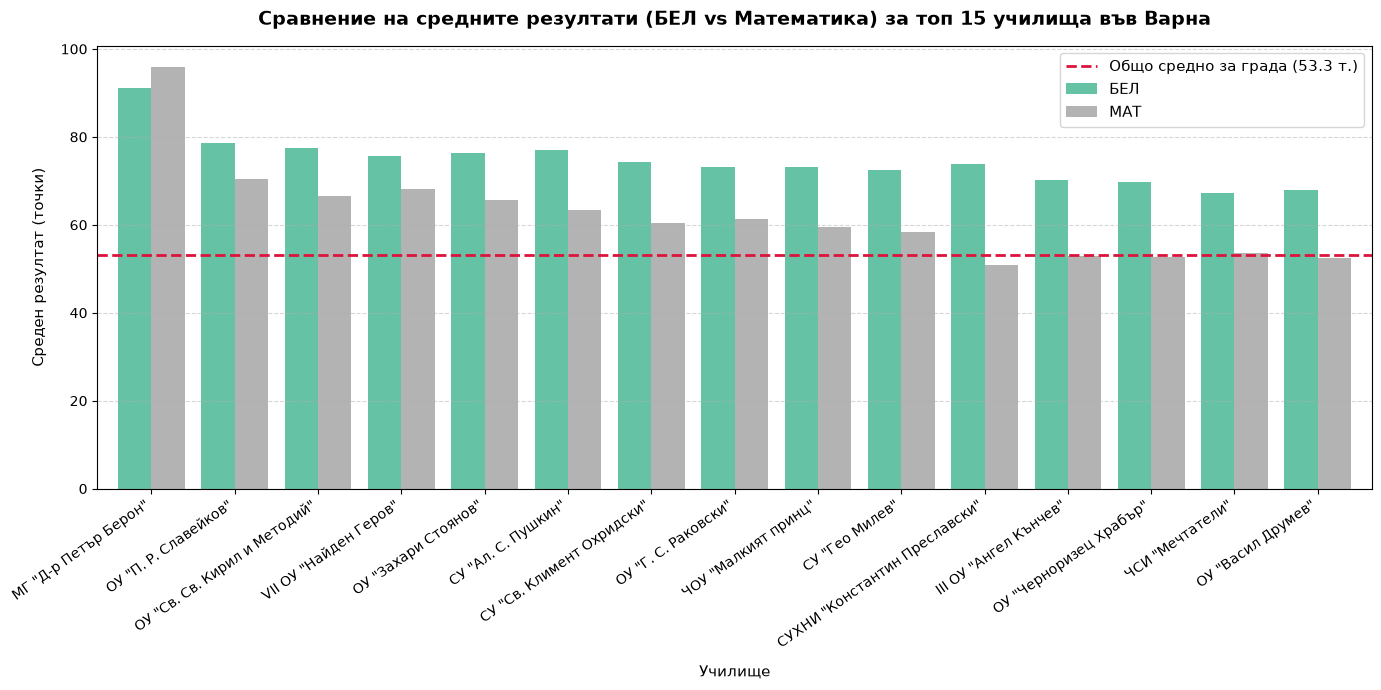

In [86]:
# Извличаме средните стойности директно от таблицата за референтната линия
city_avg_bel = city_stats.loc['mean', 'БЕЛ']
city_avg_mat = city_stats.loc['mean', 'МАТ']
overall_city_mean = (city_avg_bel + city_avg_mat) / 2

# Подготовка на данните за графиката
top_15_barplot_data = df_top15.groupby('Училище')[['БЕЛ', 'МАТ']].mean().loc[top_15_schools]

plt.figure(figsize=(14, 7))
ax = top_15_barplot_data.plot(kind='bar', figsize=(14, 7), colormap='Set2', width=0.8)

# Добавяне на червена референтна линия за общото средно ниво за града
plt.axhline(y=overall_city_mean, color='crimson', linestyle='--', linewidth=2, 
            label=f'Общо средно за града ({overall_city_mean:.1f} т.)')

# Настройки на графиката
plt.title('Сравнение на средните резултати (БЕЛ vs Математика) за топ 15 училища във Варна', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Училище', fontsize=11, labelpad=10)
plt.ylabel('Среден резултат (точки)', fontsize=11, labelpad=10)

plt.xticks(rotation=35, ha='right', fontsize=10)

plt.legend(fontsize=11, frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()


In [87]:
# Записване на готовата графика
plt.savefig('top_15_schools_vs_city_average.png', dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

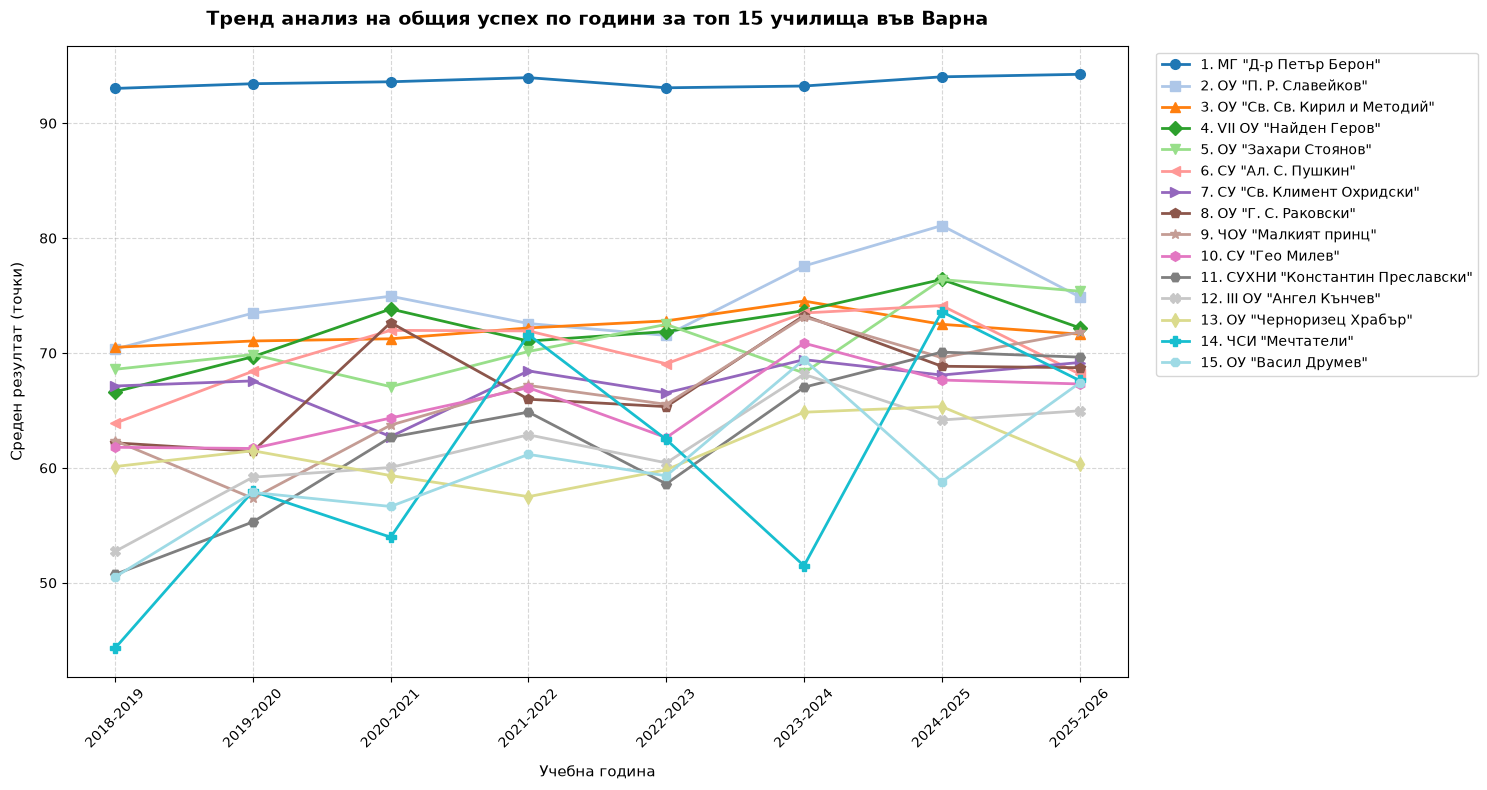

In [88]:
# ==========================================
# 4. ТРЕНД АНАЛИЗ ПО ГОДИНИ ЗА ТОП 15 УЧИЛИЩА
# ==========================================
# Изчисляваме общ успех (БЕЛ + МАТ) по години за всяко училище
df_top15['Общ_Успех'] = (df_top15['БЕЛ'] + df_top15['МАТ']) / 2
trend_pivot = df_top15.pivot_table(index='Година', columns='Училище', values='Общ_Успех')

# Сортираме колоните (училищата) спрямо средния им успех за всички години, за да са подредени и в легендата
sorted_schools = top_15_schools  # ползваме вече подредения ни списък
trend_pivot = trend_pivot[sorted_schools]

# 2. Настройване на уникални цветове и маркер стилове
plt.figure(figsize=(15, 8))

# Ползваме палитра с 20 уникални цвята
colors = plt.cm.tab20(np.linspace(0, 1, len(sorted_schools)))
markers = ['o', 's', '^', 'D', 'v', '<', '>', 'p', '*', 'h', 'H', 'X', 'd', 'P', '8']

# Чертаем всяко училище с уникален цвят и маркер
for i, school in enumerate(sorted_schools):
    plt.plot(trend_pivot.index, trend_pivot[school], 
             label=f"{i+1}. {school}", 
             color=colors[i], 
             marker=markers[i % len(markers)], 
             linewidth=2, 
             markersize=7)

plt.title('Тренд анализ на общия успех по години за топ 15 училища във Варна', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Учебна година', fontsize=11, labelpad=10)
plt.ylabel('Среден резултат (точки)', fontsize=11, labelpad=10)

plt.xticks(rotation=45, fontsize=10)
# Поставяме легендата вдясно извън графиката за максимална прегледност
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10, frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

In [89]:
# Записване на графиката
plt.savefig('schools_trend_analysis_clear.png', dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

--- КОРЕЛАЦИОННА МАТРИЦА (БЕЛ vs МАТ) ---


,БЕЛ,МАТ
БЕЛ,1.0000,0.8959
МАТ,0.8959,1.0000



Коефициент на корелация на Пирсън между БЕЛ и МАТ: 0.90


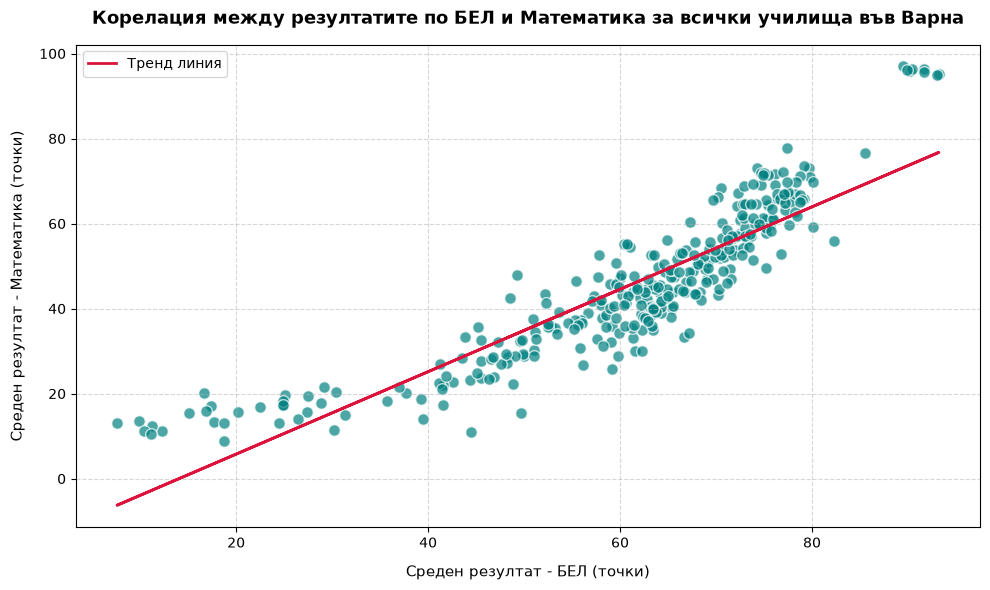

In [90]:
# ==========================================
# 5. КОРЕЛАЦИОНЕН АНАЛИЗ МЕЖДУ БЕЛ И МАТЕМАТИКА (Само с Matplotlib)
# ==========================================
# Изчисляване на матрицата на корелация
correlation_matrix = df[['БЕЛ', 'МАТ']].corr(method='pearson')
print("--- КОРЕЛАЦИОННА МАТРИЦА (БЕЛ vs МАТ) ---")
display(correlation_matrix.round(4))

corr_value = correlation_matrix.loc['БЕЛ', 'МАТ']
print(f"\nКоефициент на корелация на Пирсън между БЕЛ и МАТ: {corr_value:.2f}")

# Визуализация с точечна диаграма
plt.figure(figsize=(10, 6))
plt.scatter(df['БЕЛ'], df['МАТ'], alpha=0.7, color='teal', s=70, edgecolors='w')

# Добавяне на тренд линия (линейна регресия с numpy)
m, b = np.polyfit(df['БЕЛ'], df['МАТ'], 1)
plt.plot(df['БЕЛ'], m*df['БЕЛ'] + b, color='crimson', linewidth=2, label='Тренд линия')

plt.title('Корелация между резултатите по БЕЛ и Математика за всички училища във Варна', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Среден резултат - БЕЛ (точки)', fontsize=11, labelpad=10)
plt.ylabel('Среден резултат - Математика (точки)', fontsize=11, labelpad=10)

plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

In [91]:
plt.savefig('bel_vs_mat_correlation.png', dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

In [92]:
# ==========================================
# 6. МОМЕНТИ НА РАЗПРЕДЕЛЕНИЕТО (Skewness & Kurtosis с тълкуване)
# ==========================================
skew_bel = df['БЕЛ'].skew()
skew_mat = df['МАТ'].skew()

kurt_bel = df['БЕЛ'].kurtosis()
kurt_mat = df['МАТ'].kurtosis()

print("=" * 60)
print(" АНАЛИЗ НА МОМЕНТИТЕ НА РАЗПРЕДЕЛЕНИЕТО ЗА ВАРНЕНСКИТЕ УЧИЛИЩА ")
print("=" * 60)

print(f"\n1. БЪЛГАРСКИ ЕЗИК И ЛИТЕРАТУРА (БЕЛ):")
print(f"   - Асиметрия (Skewness = {skew_bel:.4f}):", end=" ")
if skew_bel < -0.5:
    print("Отрицателна асиметрия. Разпределението е изтеглено наляво, което означава, че повечето училища постигат по-високи резултати, а малка група институции теглят средното надолу.")
elif skew_bel > 0.5:
    print("Положителна асиметрия. Повечето училища са с по-ниски резултати, а малък брой елитни формират дълга опашка нагоре.")
else:
    print("Близо до симетрично разпределение.")

print(f"   - Острота (Kurtosis = {kurt_bel:.4f}):", end=" ")
if kurt_bel > 0:
    print("Лептокуртично разпределение (по-остър връх и по-дебели опашки) – резултатите са концентрирани около средното с изявени екстремни стойности (много силни или много слаби училища).")
else:
    print("Платикуртично разпределение – резултатите са по-равномерно разпръснати.")

print(f"\n2. МАТЕМАТИКА (МАТ):")
print(f"   - Асиметрия (Skewness = {skew_mat:.4f}):", end=" ")
if abs(skew_mat) <= 0.5:
    print("Много ниска асиметрия. Разпределението е относително симетрично и балансирано около средната стойност за града.")
elif skew_mat > 0.5:
    print("Положителна асиметрия – струпване на училища с по-ниски резултати и малък брой изявени отличници.")
else:
    print("Отрицателна асиметрия – струпване към по-високите резултати.")

print(f"   - Острота (Kurtosis = {kurt_mat:.4f}):", end=" ")
if abs(kurt_mat) < 0.5:
    print("Нормално / умерено разпределение без екстремни струпвания или резки отклонения.")
else:
    print("По-остро или по-плоско разпределение спрямо нормалната крива.")
print("=" * 60)

 АНАЛИЗ НА МОМЕНТИТЕ НА РАЗПРЕДЕЛЕНИЕТО ЗА ВАРНЕНСКИТЕ УЧИЛИЩА 

1. БЪЛГАРСКИ ЕЗИК И ЛИТЕРАТУРА (БЕЛ):
   - Асиметрия (Skewness = -1.1434): Отрицателна асиметрия. Разпределението е изтеглено наляво, което означава, че повечето училища постигат по-високи резултати, а малка група институции теглят средното надолу.
   - Острота (Kurtosis = 1.2844): Лептокуртично разпределение (по-остър връх и по-дебели опашки) – резултатите са концентрирани около средното с изявени екстремни стойности (много силни или много слаби училища).

2. МАТЕМАТИКА (МАТ):
   - Асиметрия (Skewness = 0.2490): Много ниска асиметрия. Разпределението е относително симетрично и балансирано около средната стойност за града.
   - Острота (Kurtosis = 0.1427): Нормално / умерено разпределение без екстремни струпвания или резки отклонения.


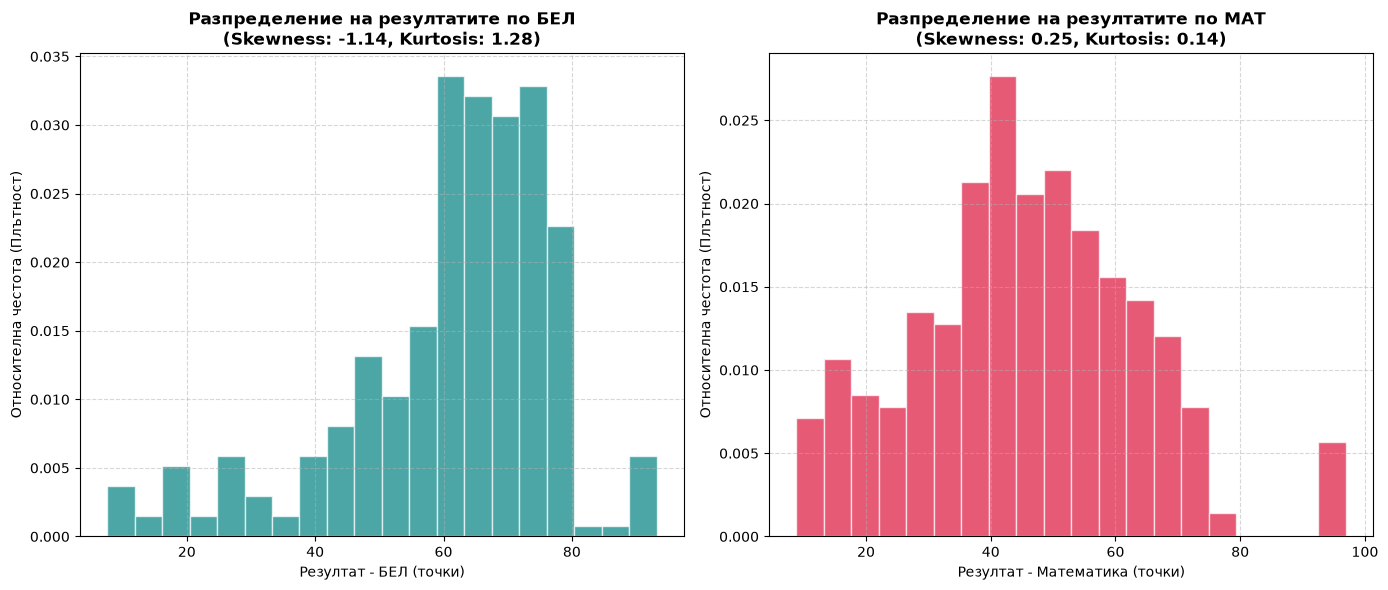

In [93]:
# ВИЗУАЛИЗАЦИЯ НА МОМЕНТИТЕ НА РАЗПРЕДЕЛЕНИЕТО (Само с Matplotlib)
# ==========================================
plt.figure(figsize=(14, 6))

# Графика 1: Разпределение за БЕЛ
plt.subplot(1, 2, 1)
plt.hist(df['БЕЛ'].dropna(), bins=20, density=True, color='teal', alpha=0.7, edgecolor='white')
plt.title(f'Разпределение на резултатите по БЕЛ\n(Skewness: {skew_bel:.2f}, Kurtosis: {kurt_bel:.2f})', fontsize=12, fontweight='bold')
plt.xlabel('Резултат - БЕЛ (точки)', fontsize=10)
plt.ylabel('Относителна честота (Плътност)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

# Графика 2: Разпределение за Математика
plt.subplot(1, 2, 2)
plt.hist(df['МАТ'].dropna(), bins=20, density=True, color='crimson', alpha=0.7, edgecolor='white')
plt.title(f'Разпределение на резултатите по МАТ\n(Skewness: {skew_mat:.2f}, Kurtosis: {kurt_mat:.2f})', fontsize=12, fontweight='bold')
plt.xlabel('Резултат - Математика (точки)', fontsize=10)
plt.ylabel('Относителна честота (Плътност)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

In [94]:
plt.savefig('distribution_moments_analysis.png', dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

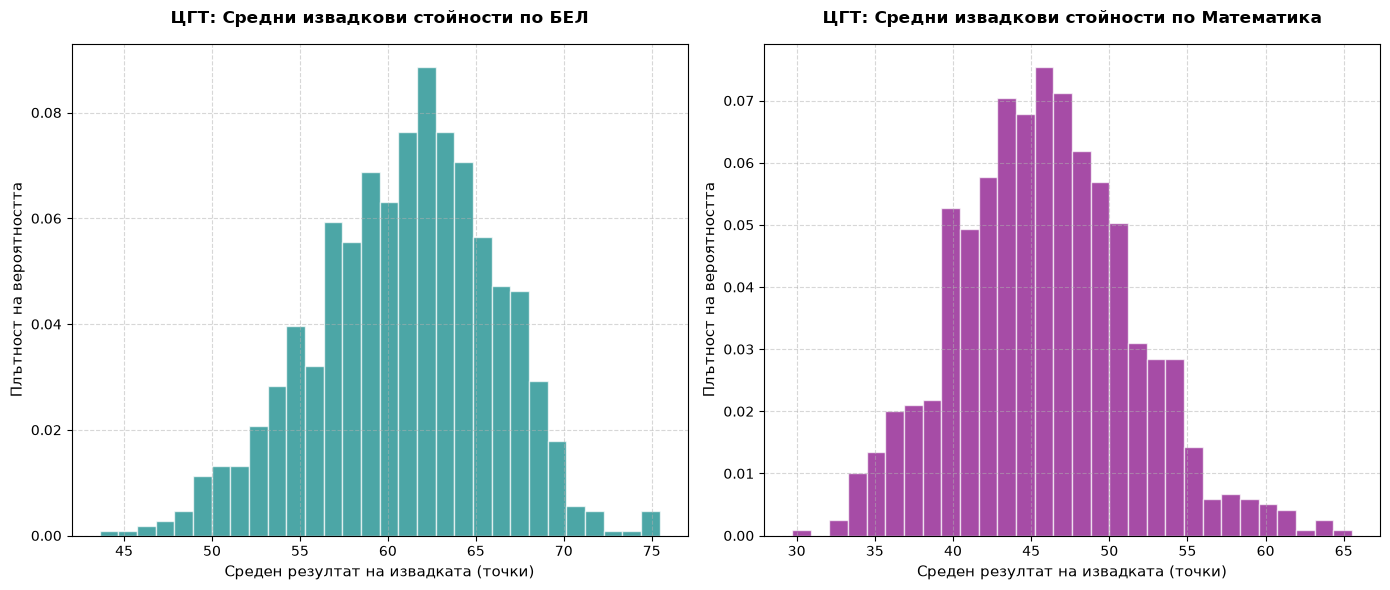

In [95]:
# ==========================================
# 7. ЦЕНТРАЛНА ГРАНИЧНА ТЕОРЕМА (Central Limit Theorem - CLT)
# ==========================================
# Използваме резултатите по Математика като наша генерална съвкупност
pop_bel = df['БЕЛ'].dropna()
pop_mat = df['МАТ'].dropna()

sample_size = 10       
num_samples = 1000     

# Симулация за БЕЛ
bel_sample_means = []
for _ in range(num_samples):
    sample = np.random.choice(pop_bel, size=sample_size, replace=True)
    bel_sample_means.append(np.mean(sample))

# Симулация за Математика
mat_sample_means = []
for _ in range(num_samples):
    sample = np.random.choice(pop_mat, size=sample_size, replace=True)
    mat_sample_means.append(np.mean(sample))

# Визуализация с две подграфики
plt.figure(figsize=(14, 6))

# Графика 1: БЕЛ
plt.subplot(1, 2, 1)
plt.hist(bel_sample_means, bins=30, density=True, color='teal', alpha=0.7, edgecolor='white')
plt.title('ЦГТ: Средни извадкови стойности по БЕЛ', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Среден резултат на извадката (точки)', fontsize=11)
plt.ylabel('Плътност на вероятността', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

# Графика 2: Математика
plt.subplot(1, 2, 2)
plt.hist(mat_sample_means, bins=30, density=True, color='purple', alpha=0.7, edgecolor='white')
plt.title('ЦГТ: Средни извадкови стойности по Математика', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Среден резултат на извадката (точки)', fontsize=11)
plt.ylabel('Плътност на вероятността', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

In [96]:
plt.savefig('central_limit_theorem_both.png', dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

In [97]:
# ==========================================
# 8. АНАЛИЗ НА АУТЛАЙЪРИ / АНОМАЛИИ (IQR Метод)
# ==========================================
def find_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

outliers_bel, low_b_bel, up_b_bel = find_outliers(df, 'БЕЛ')
outliers_mat, low_b_mat, up_b_mat = find_outliers(df, 'МАТ')

print("--- АУТЛАЙЪРИ ПО БЕЛ ---")
print(f"Долна граница: {low_b_bel:.2f}, Горна граница: {up_b_bel:.2f}")
print(f"Брой открити аномални училища/випуски: {len(outliers_bel)}")
if len(outliers_bel) > 0:
    display(outliers_bel[['Година', 'Училище', 'БЕЛ']].head(5))

print("\n--- АУТЛАЙЪРИ ПО МАТЕМАТИКА ---")
print(f"Долна граница: {low_b_mat:.2f}, Горна граница: {up_b_mat:.2f}")
print(f"Брой открити аномални училища/випуски: {len(outliers_mat)}")
if len(outliers_mat) > 0:
    display(outliers_mat[['Година', 'Училище', 'МАТ']].head(5))

--- АУТЛАЙЪРИ ПО БЕЛ ---
Долна граница: 27.01, Горна граница: 99.81
Брой открити аномални училища/випуски: 21


,Година,Училище,БЕЛ
128,2025-2026,"ОУ ""Отец Паисий""",12.30
129,2024-2025,"ОУ ""Отец Паисий""",17.34
130,2023-2024,"ОУ ""Отец Паисий""",16.67
131,2022-2023,"ОУ ""Отец Паисий""",9.86
132,2021-2022,"ОУ ""Отец Паисий""",11.18



--- АУТЛАЙЪРИ ПО МАТЕМАТИКА ---
Долна граница: -0.12, Горна граница: 91.65
Брой открити аномални училища/випуски: 8


,Година,Училище,МАТ
32,2025-2026,"МГ ""Д-р Петър Берон""",95.30
33,2024-2025,"МГ ""Д-р Петър Берон""",95.01
34,2023-2024,"МГ ""Д-р Петър Берон""",96.95
35,2022-2023,"МГ ""Д-р Петър Берон""",95.98
36,2021-2022,"МГ ""Д-р Петър Берон""",96.31


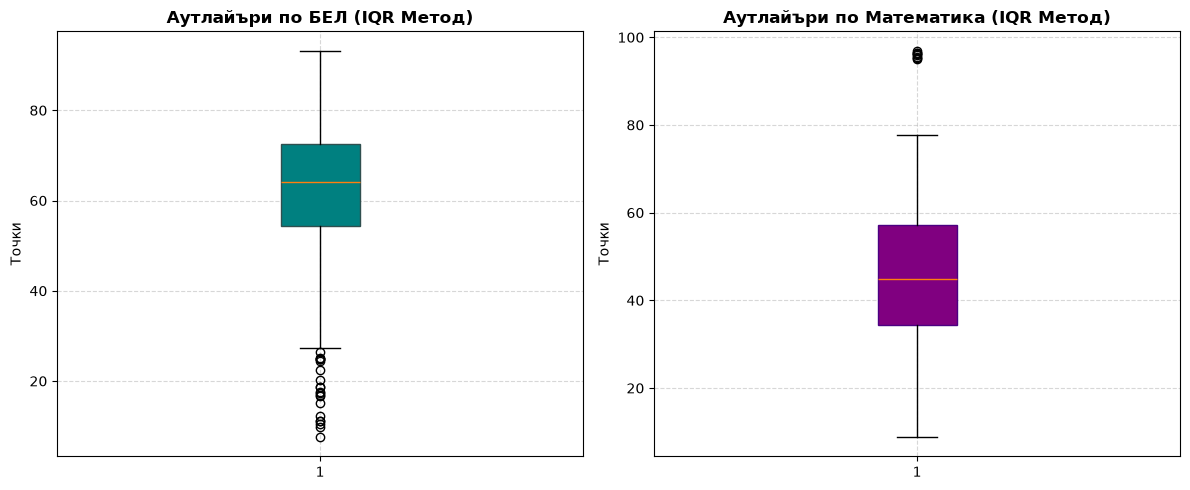

In [101]:
# ==========================================
# ВИЗУАЛИЗАЦИЯ НА АУТЛАЙЪРИТЕ (Boxplot)
# ==========================================
plt.figure(figsize=(12, 5))

# Подграфика 1: БЕЛ
plt.subplot(1, 2, 1)
bp_bel = plt.boxplot(df['БЕЛ'].dropna(), patch_artist=True, 
                     boxprops=dict(facecolor='teal', color='darkslategray'),
                     flierprops=dict(marker='o', color='crimson', markersize=6))
plt.title('Аутлайъри по БЕЛ (IQR Метод)', fontsize=12, fontweight='bold')
plt.ylabel('Точки', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

# Подграфика 2: Математика
plt.subplot(1, 2, 2)
bp_mat = plt.boxplot(df['МАТ'].dropna(), patch_artist=True, 
                     boxprops=dict(facecolor='purple', color='indigo'),
                     flierprops=dict(marker='o', color='crimson', markersize=6))
plt.title('Аутлайъри по Математика (IQR Метод)', fontsize=12, fontweight='bold')
plt.ylabel('Точки', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('outliers_boxplot.png', dpi=300)
plt.show()

In [99]:
# ==========================================
# 9. АНАЛИЗ НА ВАРИАЦИЯТА (ANOVA по години)
# ==========================================
from scipy.stats import f_oneway

# Подготвяме групите по години за Математика и БЕЛ
years = sorted(df['Година'].dropna().unique())

groups_mat = [df[df['Година'] == year]['МАТ'].dropna() for year in years]
groups_bel = [df[df['Година'] == year]['БЕЛ'].dropna() for year in years]

# Изчисляване на ANOVA
f_stat_mat, p_val_mat = f_oneway(*groups_mat)
f_stat_bel, p_val_bel = f_oneway(*groups_bel)

print("=" * 50)
print(" ЕДНОФАКТОРЕН АНАЛИЗ НА ВАРИАЦИЯТА (ANOVA ПО ГОДИНИ) ")
print("=" * 50)
print(f"1. МАТЕМАТИКА:")
print(f"   - F-статистика: {f_stat_mat:.4f}")
print(f"   - p-value: {p_val_mat:.4e}")
if p_val_mat < 0.05:
    print("   -> Извод: Има статистически значима разлика в резултатите по Математика между различните години.")
else:
    print("   -> Извод: Няма статистически значима разлика по години – нивото е стабилно във времето.")

print(f"\n2. БЪЛГАРСКИ ЕЗИК И ЛИТЕРАТУРА (БЕЛ):")
print(f"   - F-статистика: {f_stat_bel:.4f}")
print(f"   - p-value: {p_val_bel:.4e}")
if p_val_bel < 0.05:
    print("   -> Извод: Има статистически значима разлика в резултатите по БЕЛ между различните години.")
else:
    print("   -> Извод: Няма статистически значима разлика по години – нивото е стабилно във времето.")
print("=" * 50)

 ЕДНОФАКТОРЕН АНАЛИЗ НА ВАРИАЦИЯТА (ANOVA ПО ГОДИНИ) 
1. МАТЕМАТИКА:
   - F-статистика: 2.2372
   - p-value: 3.1179e-02
   -> Извод: Има статистически значима разлика в резултатите по Математика между различните години.

2. БЪЛГАРСКИ ЕЗИК И ЛИТЕРАТУРА (БЕЛ):
   - F-статистика: 0.4202
   - p-value: 8.8949e-01
   -> Извод: Няма статистически значима разлика по години – нивото е стабилно във времето.


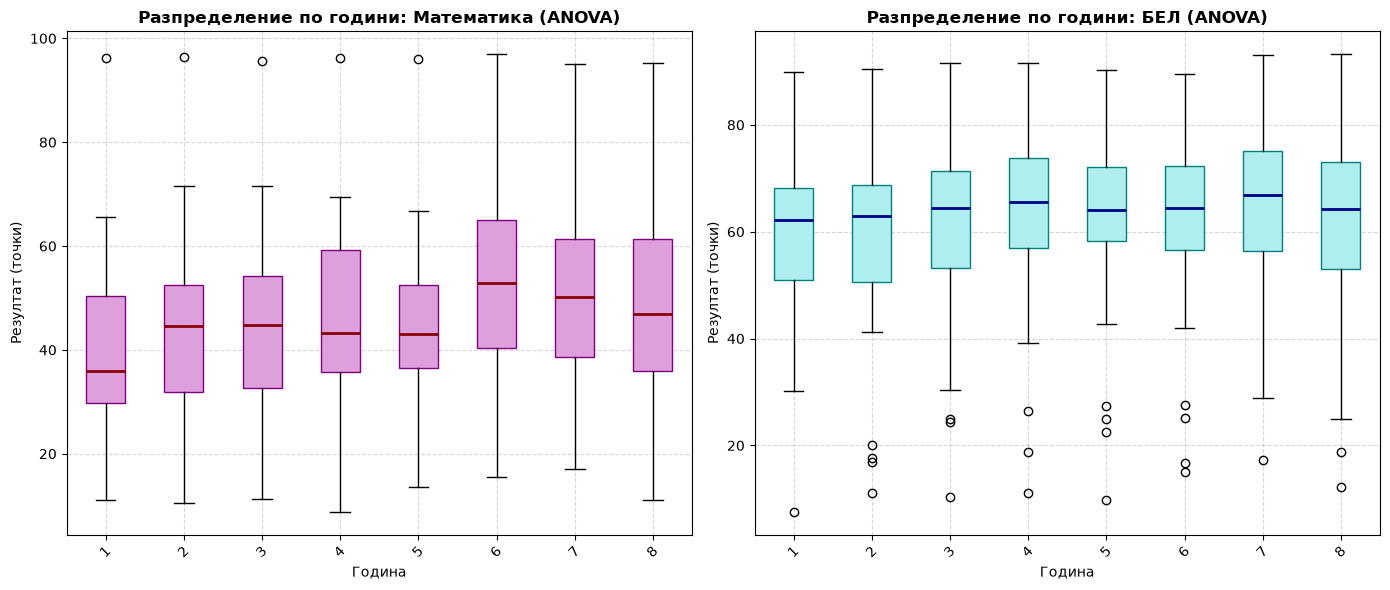

In [104]:
# ==========================================
# ВИЗУАЛИЗАЦИЯ ЗА ANOVA (Сравнение по години)
# ==========================================
plt.figure(figsize=(14, 6))

# Подготовка на данните за подаване към matplotlib boxplot
data_by_year_mat = [df[df['Година'] == y]['МАТ'].dropna() for y in years]
data_by_year_bel = [df[df['Година'] == y]['БЕЛ'].dropna() for y in years]

# Графика за Математика по години
plt.subplot(1, 2, 1)
plt.boxplot(data_by_year_mat, label=years, patch_artist=True,
            boxprops=dict(facecolor='plum', color='purple'),
            medianprops=dict(color='darkred', linewidth=2))
plt.title('Разпределение по години: Математика (ANOVA)', fontsize=12, fontweight='bold')
plt.xlabel('Година', fontsize=10)
plt.ylabel('Резултат (точки)', fontsize=10)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)

# Графика за БЕЛ по години
plt.subplot(1, 2, 2)
plt.boxplot(data_by_year_bel, label=years, patch_artist=True,
            boxprops=dict(facecolor='paleturquoise', color='teal'),
            medianprops=dict(color='darkblue', linewidth=2))
plt.title('Разпределение по години: БЕЛ (ANOVA)', fontsize=12, fontweight='bold')
plt.xlabel('Година', fontsize=10)
plt.ylabel('Резултат (точки)', fontsize=10)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('anova_years_boxplot.png', dpi=300)
plt.show()

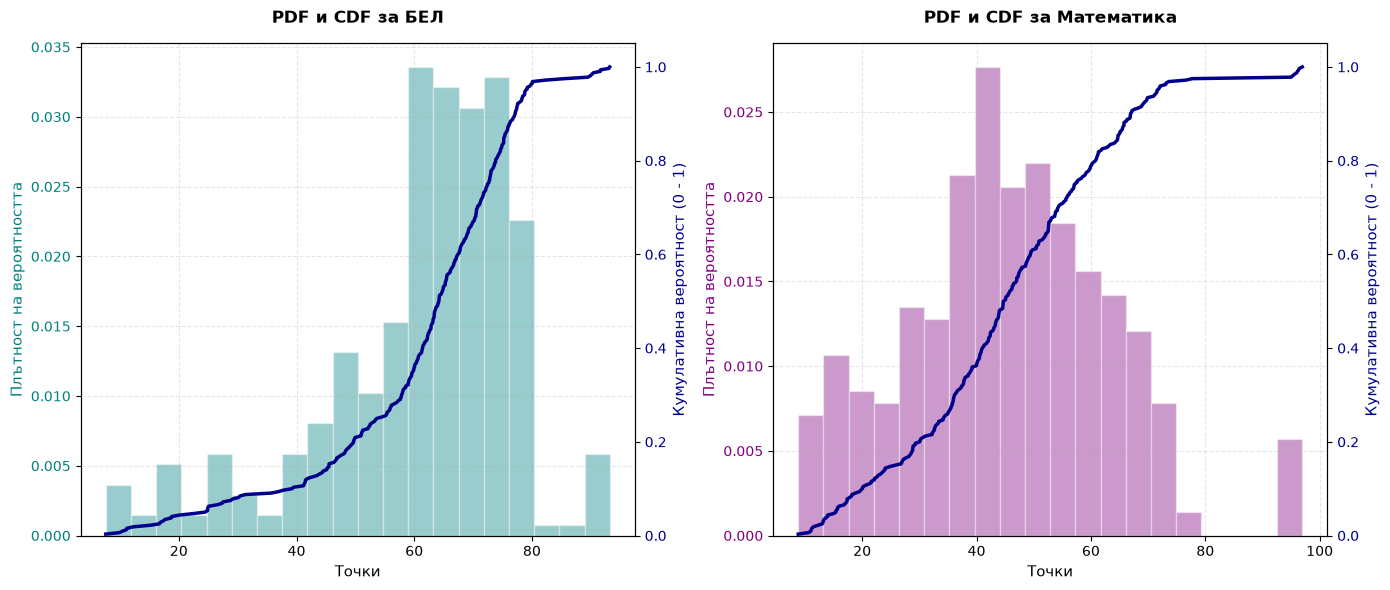

In [110]:
# ==========================================
# 10. PDF И CDF С ДВЕ ОСИ (Двойно мащабиране)
# ==========================================
fig, (ax1_bel, ax1_mat) = plt.subplots(1, 2, figsize=(14, 6))

def plot_dual_pdf_cdf(ax, data, color, title):
    clean_data = data.dropna().sort_values()
    
    # Лява ос (AX1): PDF - Плътност (Хистограма)
    n, bins, patches = ax.hist(clean_data, bins=20, density=True, color=color, alpha=0.4, edgecolor='white', label='PDF (Плътност)')
    ax.set_xlabel('Точки', fontsize=11)
    ax.set_ylabel('Плътност на вероятността', fontsize=11, color=color)
    ax.tick_params(axis='y', labelcolor=color)
    ax.grid(True, linestyle='--', alpha=0.3)
    
    # Дясна ос (AX2): CDF - Кумулативно разпределение (0 до 1)
    ax2 = ax.twinx()
    cdf_vals = np.arange(1, len(clean_data) + 1) / len(clean_data)
    ax2.plot(clean_data, cdf_vals, color='darkblue', linewidth=2.5, label='CDF (Кумулативна)')
    ax2.set_ylabel('Кумулативна вероятност (0 - 1)', fontsize=11, color='darkblue')
    ax2.tick_params(axis='y', labelcolor='darkblue')
    ax2.set_ylim(0, 1.05)
    
    ax.set_title(title, fontsize=12, fontweight='bold', pad=15)

# Рисуваме за БЕЛ
plot_dual_pdf_cdf(ax1_bel, df['БЕЛ'], 'teal', 'PDF и CDF за БЕЛ')

# Рисуваме за Математика
plot_dual_pdf_cdf(ax1_mat, df['МАТ'], 'purple', 'PDF и CDF за Математика')

plt.tight_layout()
plt.savefig('pdf_cdf_dual_axis.png', dpi=300)
plt.show()

In [109]:
# ==========================================
# 11. ТЕСТ ЗА ПАРАДОКСА НА СИМПСЪН (По години)
# ==========================================
print("=" * 60)
print(" КОРЕЛАЦИЯ МЕЖДУ БЕЛ И МАТ ПО ГОДИНИ (Симпсън парадокс тест) ")
print("=" * 60)

overall_corr = df['БЕЛ'].corr(df['МАТ'])
print(f"Обща корелация за целия период (всички години): {overall_corr:.4f}\n")

print("Корелация по отделни години:")
years = sorted(df['Година'].dropna().unique())
for year in years:
    subset = df[df['Година'] == year]
    yearly_corr = subset['БЕЛ'].corr(subset['МАТ'])
    print(f" - Година {year}: Корелация = {yearly_corr:.4f} (брой училища: {len(subset)})")

print("=" * 60)
print("Ако общата корелация е силна, но в отделните години е съвсем слаба (или обратна), това е класически Парадокс на Симпсън.")

 КОРЕЛАЦИЯ МЕЖДУ БЕЛ И МАТ ПО ГОДИНИ (Симпсън парадокс тест) 
Обща корелация за целия период (всички години): 0.8959

Корелация по отделни години:
 - Година 2018-2019: Корелация = 0.8604 (брой училища: 40)
 - Година 2019-2020: Корелация = 0.9143 (брой училища: 40)
 - Година 2020-2021: Корелация = 0.9100 (брой училища: 40)
 - Година 2021-2022: Корелация = 0.8966 (брой училища: 40)
 - Година 2022-2023: Корелация = 0.8861 (брой училища: 40)
 - Година 2023-2024: Корелация = 0.9278 (брой училища: 40)
 - Година 2024-2025: Корелация = 0.9513 (брой училища: 40)
 - Година 2025-2026: Корелация = 0.9404 (брой училища: 40)
Ако общата корелация е силна, но в отделните години е съвсем слаба (или обратна), това е класически Парадокс на Симпсън.


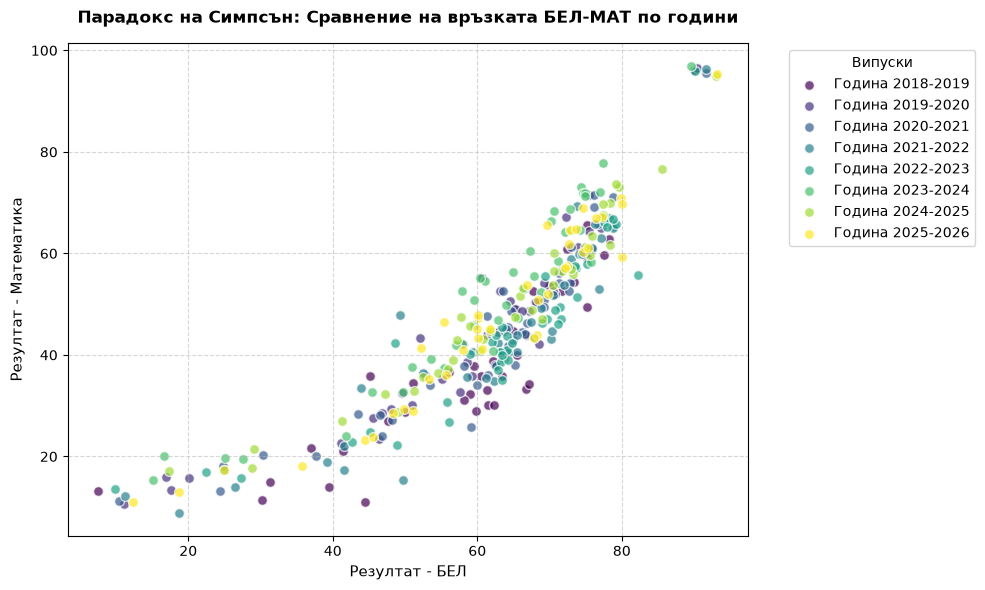

In [112]:
# ==========================================
# 11. ВИЗУАЛИЗАЦИЯ НА ПАРАДОКСА НА СИМПСЪН
# ==========================================
plt.figure(figsize=(10, 6))

years = sorted(df['Година'].dropna().unique())
colors = plt.cm.viridis(np.linspace(0, 1, len(years)))

for year, color in zip(years, colors):
    subset = df[df['Година'] == year]
    plt.scatter(subset['БЕЛ'], subset['МАТ'], color=color, alpha=0.7, edgecolors='w', s=50, label=f'Година {year}')

plt.title('Парадокс на Симпсън: Сравнение на връзката БЕЛ-МАТ по години', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Резултат - БЕЛ', fontsize=11)
plt.ylabel('Резултат - Математика', fontsize=11)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Випуски")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('simpsons_paradox_plot.png', dpi=300)
plt.show()